In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import yaml
from icecream import ic

from bandit_sim.configs import AlgorithmConfig, BanditEnvConfig
from bandit_sim.setting import Settings, generate_base_filename

In [2]:
result_dir = "20250920-1221-alignment"
output_dir = os.path.join("../output/", result_dir)

config = {}

with open(os.path.join(output_dir, "simulation_config.yaml"), "r") as config_file:
    raw_dict = yaml.full_load(config_file)  # TODO: Make config loadable.
    for k, v in raw_dict.items():
        if k == "bandit_env_config":
            config_value = BanditEnvConfig.model_validate(v)
        elif k == "algorithm_configs":
            config_value = [AlgorithmConfig.model_validate(alg_dict) for alg_dict in v]
        elif k == "settings":
            config_value = Settings(**v)
        else:
            config_value = v

        config[k] = config_value

settings: Settings = config["settings"]
algorithms: list[AlgorithmConfig] = config["algorithm_configs"]
bandit_env_config = config["bandit_env_config"]
bandit_env_name = config["bandit_env_name"]

# config
T = settings.T
trials = settings.num_trials
K = settings.num_arms
base_seed = settings.base_seed

num_trials = settings.num_trials
trial_id_overrides = settings.trial_id_overrides

if trial_id_overrides is not None and len(trial_id_overrides) > 0:
    trial_ids = trial_id_overrides
    num_trials = len(trial_ids)
else:
    trial_ids = range(num_trials)

num_algs = len(algorithms)
K_env = K // 2

In [3]:
bandit_env_params = None
filename = generate_base_filename(base_seed)

with open(os.path.join(output_dir, f"bandit_env_params_{filename}"), "rb") as f:
    bandit_env_params = np.load(f)

ic(bandit_env_params.shape)
ic(bandit_env_params)

ic| bandit_env_params.shape: (8, 16, 2)
ic| bandit_env_params: array([[[0.13213638, 0.77931175],
                               [0.34527982, 0.71771169],
                               [0.7921504 , 0.38719485],
                               [0.43115371, 0.7627061 ],
                               [0.40091281, 0.8196303 ],
                               [0.80349924, 0.63781577],
                               [0.56304025, 0.92486143],
                               [0.64060494, 0.74120804],
                               [0.76478403, 0.62653625],
                               [0.85523206, 0.78154398],
                               [0.58753563, 0.61761012],
                               [0.00596389, 0.93527292],
                               [0.10233818, 0.75784936],
                               [0.780643  , 0.56353668],
                               [0.1954781 , 0.90503785],
                               [0.18849304, 0.52485809]],
                       
                       

array([[[0.13213638, 0.77931175],
        [0.34527982, 0.71771169],
        [0.7921504 , 0.38719485],
        [0.43115371, 0.7627061 ],
        [0.40091281, 0.8196303 ],
        [0.80349924, 0.63781577],
        [0.56304025, 0.92486143],
        [0.64060494, 0.74120804],
        [0.76478403, 0.62653625],
        [0.85523206, 0.78154398],
        [0.58753563, 0.61761012],
        [0.00596389, 0.93527292],
        [0.10233818, 0.75784936],
        [0.780643  , 0.56353668],
        [0.1954781 , 0.90503785],
        [0.18849304, 0.52485809]],

       [[0.75134878, 0.08816835],
        [0.14145237, 0.30003313],
        [0.29234305, 0.79313498],
        [0.13721752, 0.07866908],
        [0.06409642, 0.88873913],
        [0.24422884, 0.18175223],
        [0.47068999, 0.83581107],
        [0.4912504 , 0.94570183],
        [0.48346784, 0.44090812],
        [0.14231159, 0.84481962],
        [0.62769681, 0.42529207],
        [0.2735107 , 0.90680751],
        [0.82427213, 0.64939364],
        [0.9

```
array([[[0.55816467, 0.64956509],
        [0.3924774 , 0.15434337],
        [0.52445407, 0.12741056],
        [0.76878136, 0.66354573],
        [0.52746323, 0.00325044],
        [0.70904825, 0.89618992],
        [0.1866809 , 0.22438431],
        [0.62856906, 0.97795175],
        [0.72141581, 0.67531868],
        [0.84310354, 0.10980487],
        [0.52261935, 0.8465304 ],
        [0.630737  , 0.71617729],
        [0.8527067 , 0.38089709],
        [0.51195239, 0.02751231],
        [0.40319264, 0.49528798],
        [0.72736088, 0.13100071]]])
```

In [4]:
raw_df = pl.DataFrame()

for i, trial_id in enumerate(trial_ids):
    filename = generate_base_filename(base_seed, trial_id)
    with open(os.path.join(output_dir, f"data_{filename}"), "rb") as f:
        raw_df.vstack(pl.read_parquet(f), in_place=True)

raw_df

reward,action,algorithm,time_step,regret,trial
f64,u8,cat,u32,f64,u16
0.220688,0,"""TS ep1""",0,0.479339,0
0.282288,1,"""TS ep1""",1,0.897077,0
0.387195,2,"""TS ep1""",2,1.209909,0
0.237294,3,"""TS ep1""",3,1.672642,0
0.18037,4,"""TS ep1""",4,2.192299,0
…,…,…,…,…,…
0.935478,0,"""TS-ep2""",99995,4279.060734,7
0.935478,0,"""TS-ep2""",99996,4278.964613,7
0.935478,0,"""TS-ep2""",99997,4278.868493,7


In [8]:
aggregated_df = (
    raw_df.group_by("algorithm", "time_step")
    .agg(
        pl.col("regret").mean().alias("regret mean"),
        pl.col("regret").std().alias("regret std"),
    )
    .sort("time_step")
)

grouped_df = aggregated_df.group_by("algorithm")

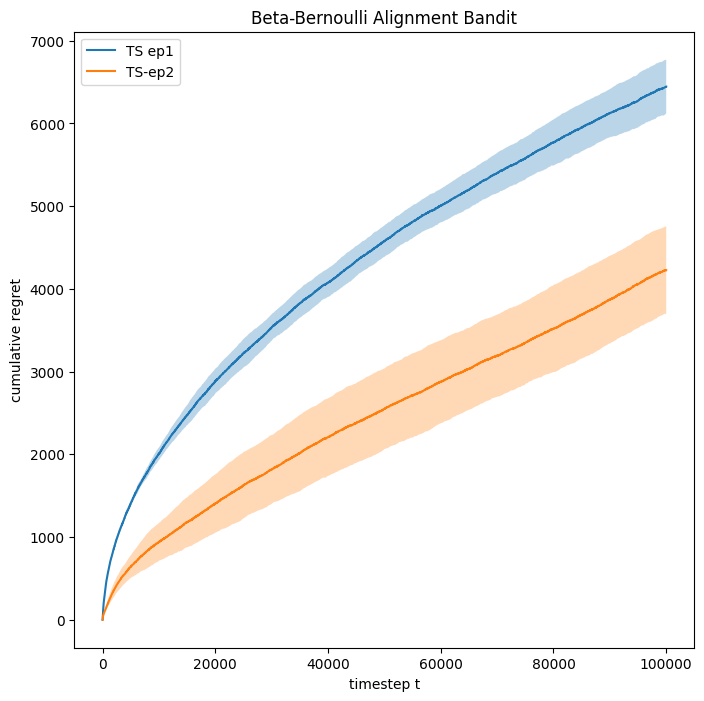

In [9]:
"""
Section below is for plotting
"""
title = bandit_env_name
output = bandit_env_config.label

plt.figure(figsize=(8, 8))

for alg_name, data in grouped_df:
    means = data["regret mean"]
    stds = data["regret std"]
    plt.plot(
        np.arange(T),
        means,
        label=alg_name,
    )
    plt.fill_between(
        np.arange(T),
        means + stds,
        means - stds,
        alpha=0.3,
    )

plt.title(title)
plt.xlabel("timestep t")
plt.ylabel("cumulative regret")
plt.legend()
plt.show()

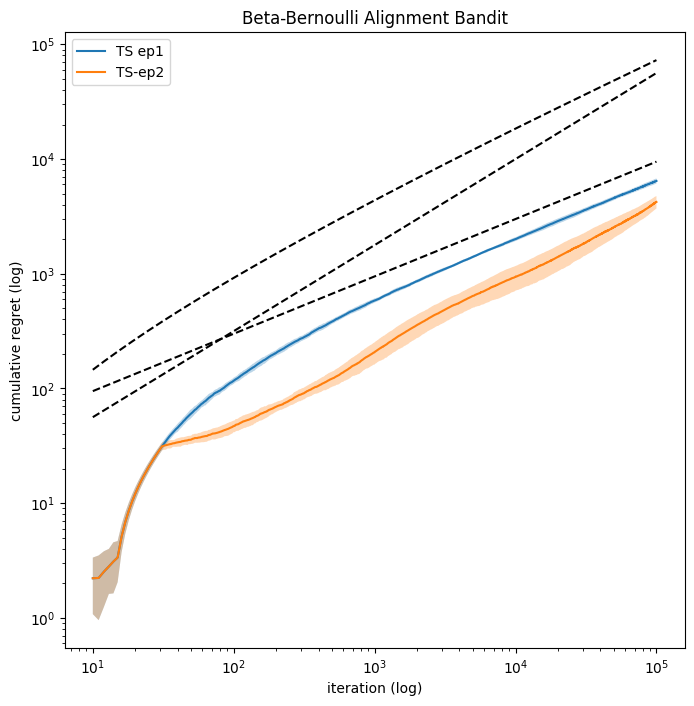

In [10]:
# log log plot
plt.figure(figsize=(8, 8))

for alg_name, data in grouped_df:
    means = data["regret mean"]
    stds = data["regret std"]
    plt.plot(
        np.arange(10, T),
        means[10:],
        label=alg_name,
    )
    plt.fill_between(
        np.arange(10, T),
        means[10:] + stds[10:],
        means[10:] - stds[10:],
        alpha=0.3,
    )
# lines for comparison
x = np.arange(10, T)
sqrt_x = 30 * np.sqrt(x)
sqrt_x_log_x = 20 * np.sqrt(x) * np.log(x)
x_3_4 = 10 * x ** (3 / 4)

# plt.plot(x, x, "k--")
plt.plot(x, sqrt_x, "k--")
plt.plot(x, sqrt_x_log_x, "k--")
plt.plot(x, x_3_4, "k--")
# plt.xlim(left=0, right=T)
# plt.ylim(bottom=0, top=120)
plt.title(title)
plt.xlabel("iteration (log)")
plt.ylabel("cumulative regret (log)")
plt.yscale("log")
plt.xscale("log")
plt.legend()
plt.show()

In [11]:
df_human_actions = (
    raw_df.with_columns(
        pl.when(pl.col("action") < K_env)
        .then(pl.lit(0))
        .otherwise(pl.lit(1))
        .alias("human action")
    )
    .with_columns(
        pl.col("human action")
        .cum_sum()
        .over("algorithm", "trial", order_by="time_step")
        .alias("cumulative human action")
    )
    .group_by("algorithm", "time_step")
    .agg(
        pl.col("cumulative human action").mean().alias("mean cum human action"),
        pl.col("cumulative human action").std().alias("std cum human action"),
    )
    .sort("time_step")
)

df_human_actions_grouped = df_human_actions.group_by("algorithm")

df_human_actions

algorithm,time_step,mean cum human action,std cum human action
cat,u32,f64,f64
"""TS-ep2""",0,0.0,0.0
"""TS ep1""",0,0.0,0.0
"""TS-ep2""",1,0.0,0.0
"""TS ep1""",1,0.0,0.0
"""TS ep1""",2,0.0,0.0
…,…,…,…
"""TS ep1""",99997,3484.0,44.439365
"""TS ep1""",99998,3484.0,44.439365
"""TS-ep2""",99998,1805.5,48.989795


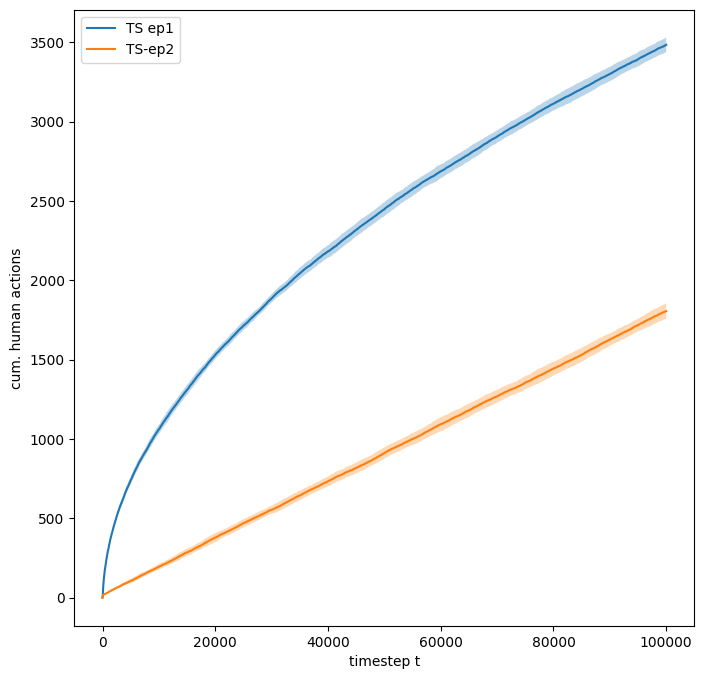

In [12]:
plt.figure(figsize=(8, 8))

for alg_name, data in df_human_actions_grouped:
    means = data["mean cum human action"]
    stds = data["std cum human action"]
    plt.plot(
        np.arange(T),
        means,
        label=alg_name,
    )
    plt.fill_between(
        np.arange(T),
        means + stds,
        means - stds,
        alpha=0.3,
    )

plt.xlabel("timestep t")
plt.ylabel("cum. human actions")
plt.legend()
plt.show()

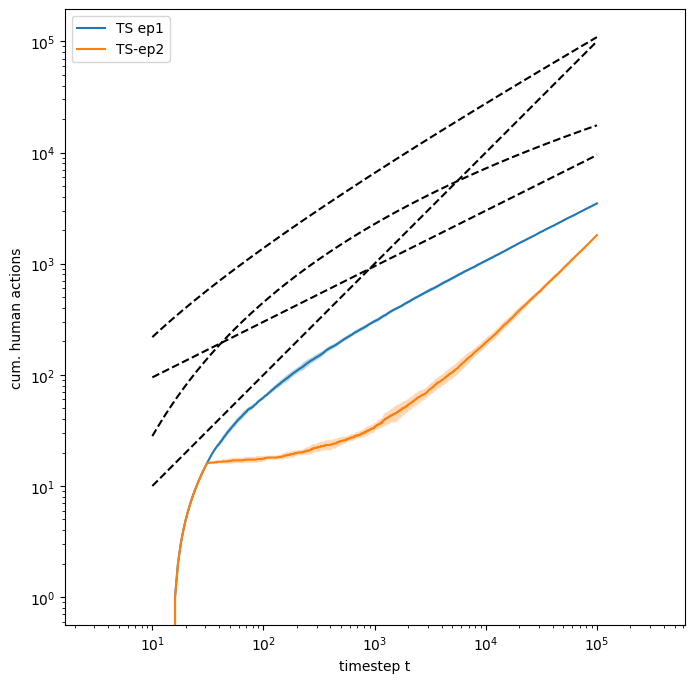

In [13]:
plt.figure(figsize=(8, 8))
for alg_name, data in df_human_actions_grouped:
    means = data["mean cum human action"][10:]
    stds = data["std cum human action"][10:]
    plt.plot(
        np.arange(10, T),
        means,
        label=alg_name,
    )
    plt.fill_between(
        np.arange(10, T),
        means + stds,
        means - stds,
        alpha=0.3,
    )

sqrt_t = np.sqrt(np.arange(10, T))
sqrt_t_log_t = np.sqrt(np.arange(10, T)) * np.log(np.arange(10, T))
log_t = np.log(np.arange(10, T)) * np.log(np.arange(10, T))

plt.plot(np.arange(10, T), np.arange(10, T), color="black", linestyle="--")
plt.plot(np.arange(10, T), 30 * sqrt_t_log_t, color="black", linestyle="--")
plt.plot(np.arange(10, T), log_t**2, color="black", linestyle="--")
plt.plot(np.arange(10, T), 30 * sqrt_t, color="black", linestyle="--")

plt.xscale("log")
plt.yscale("log")
plt.axis("equal")

plt.xlabel("timestep t")
plt.ylabel("cum. human actions")
plt.legend()
plt.show()